In [9]:
pip install numpy pandas matplotlib statsmodels

In [12]:
%pip install -U pandas python-calamine

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 61.4 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Main data loaded: (32161, 33)
FIMS data loaded: (58585, 8)

Matching diagnostic BEFORE filters:
  year  matched_rows_before_filters  distinct_children  co_residing_rows
 2017                        14862              13530              8888
 2019                        14434              13183              8715
 2021                        13156              12078              8021
 2023                        12906              11992              8000
Eligible annual matched rows: 13,630
Eligible distinct parent-child pairs: 4,198

Age summary:
        parent_age  child_age
count     13630.0    13630.0
mean         62.8       36.8
std           8.4        7.6
min          38.0       25.0
25%          57.0       31.0
50%          63.0       36.0
75%          69.0       42.0
max          85.0       55.0
Balanced 4-wave pairs: 2,074

Regression results (balanced sample):
     measure     model     beta   ci_low  ci_high    n       r2
       2017       IGE 0.251688 0.210413 0.292964 2074 

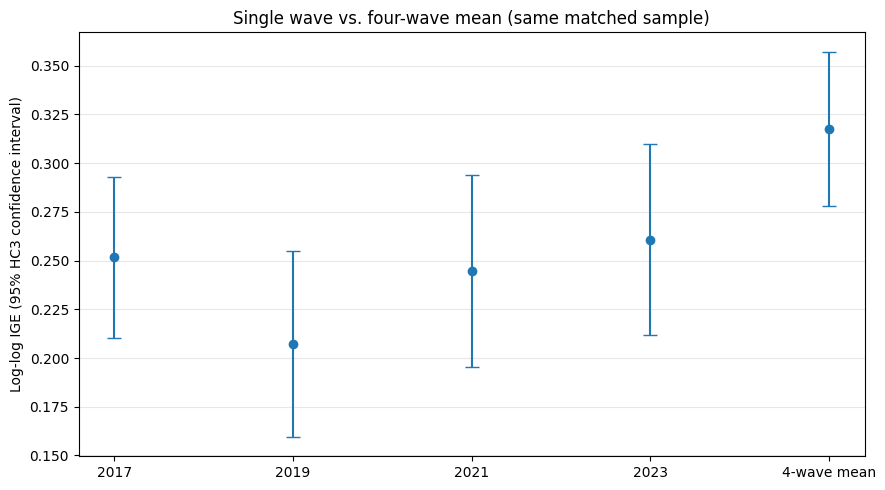

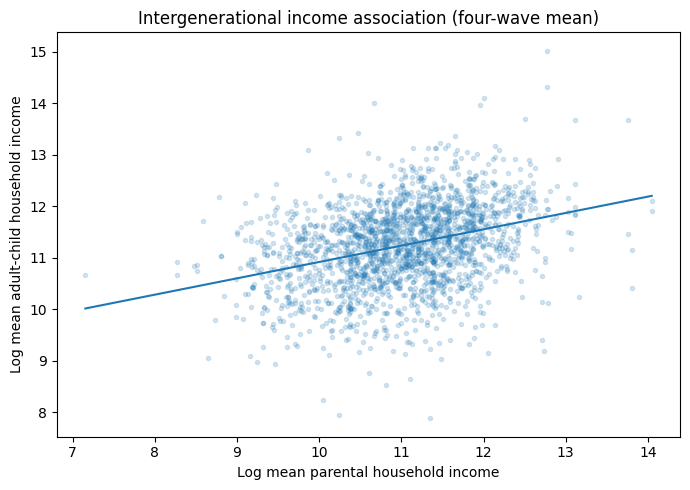


Output folder: /content/blog6_results
Interpretation warning: age-incomparable waves cannot alone identify life-cycle bias.


In [1]:
"""Blog Post 6 — local PSID SQL analysis.

Run ONLY on your own computer when authorized by the data provider.
Never upload PSID data or derived microdata to AI services.

Dependencies: pip install pandas openpyxl numpy statsmodels matplotlib
"""
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# ------ Change ONLY these paths first ------
DATA_FILE = Path('/content/J366641.xlsx')
FIMS_FILE = Path('/content/fim16231_gidpro_BO_2_BAL.xlsx')
OUTPUT = Path('blog6_results')
OUTPUT.mkdir(exist_ok=True)
YEARS = (2017, 2019, 2021, 2023)
# Optional age restrictions are descriptive only and do NOT prove life-cycle identification.
CHILD_AGE_RANGE = (25, 55)
PARENT_AGE_RANGE = (35, 85)
REQUIRE_DISTINCT_HOUSEHOLDS = True
MIN_WAVES = 2

COLUMNS = {
    2017: dict(family_id='ER34501', sequence='ER34502', age='ER34504', income='ER71426'),
    2019: dict(family_id='ER34701', sequence='ER34702', age='ER34704', income='ER77448'),
    2021: dict(family_id='ER34901', sequence='ER34902', age='ER34904', income='ER81775'),
    2023: dict(family_id='ER35101', sequence='ER35102', age='ER35104', income='ER85629'),
}

# ------ Stage 1: load locally / validate expected headers ------
raw = pd.read_excel(DATA_FILE, engine="calamine")
fims = pd.read_excel(FIMS_FILE, engine="calamine")

print("Main data loaded:", raw.shape)
print("FIMS data loaded:", fims.shape)
required_data = ['ER30001', 'ER30002'] + [col for y in YEARS for col in COLUMNS[y].values()]
required_fims = ['G1ID68', 'G1PN', 'G2ID68', 'G2PN']
missing_data = sorted(set(required_data) - set(raw.columns))
missing_fims = sorted(set(required_fims) - set(fims.columns))
if missing_data or missing_fims:
    raise ValueError(f'Missing columns in income file: {missing_data}; in FIMS file: {missing_fims}. '
                     'Recheck headers against your local PSID codebook.')

# Income fields are already attached to individual rows by PSID Data Center.
# We deliberately create normalized SQL tables so JOIN remains substantive.
people_frames = []
household_frames = []
for year in YEARS:
    cols = COLUMNS[year]
    tmp = raw[['ER30001', 'ER30002', cols['family_id'], cols['sequence'],
               cols['age'], cols['income']]].copy()
    tmp.columns = ['id68', 'pn', 'family_id', 'sequence', 'age', 'income']
    tmp.insert(0, 'year', year)
    for col in ['id68','pn','family_id','sequence','age','income']:
        tmp[col] = pd.to_numeric(tmp[col], errors='coerce')
    # A positive household ID avoids structural zero missing IDs.
    people_frames.append(tmp[['year','id68','pn','family_id','sequence','age']])
    household_frames.append(tmp[['year','family_id','income']])

people = pd.concat(people_frames, ignore_index=True)
households = pd.concat(household_frames, ignore_index=True)
households = households.dropna(subset=['family_id','income'])
households = households[households['family_id'] > 0]

# Family income should be identical for everybody in the same household and wave.
# Do not quietly resolve conflicting income entries: flag them for review.
conflicts = (households.groupby(['year','family_id'])['income']
             .nunique(dropna=True))
if (conflicts > 1).any():
    examples = conflicts[conflicts > 1].head(10)
    raise ValueError('Multiple income values for a household-year. Investigate before analysis:\n'
                     + str(examples))
households = households.drop_duplicates(['year','family_id'])

links = fims[required_fims].copy()
links.columns = ['parent_id68','parent_pn','child_id68','child_pn']
for col in links.columns:
    links[col] = pd.to_numeric(links[col], errors='coerce')
links = links.dropna().drop_duplicates()

with sqlite3.connect(':memory:') as con:
    people.to_sql('people', con, if_exists='replace', index=False)
    households.to_sql('households', con, if_exists='replace', index=False)
    links.to_sql('parent_child_links', con, if_exists='replace', index=False)

    # Stage 2: SELECT + JOIN, person-years linked to their household-year income.
    con.executescript("""
    CREATE INDEX ix_people_ids ON people(id68,pn,year);
    CREATE INDEX ix_family ON households(year,family_id);
    CREATE INDEX ix_links ON parent_child_links(parent_id68,parent_pn,child_id68,child_pn);
    """)
    # Review PSID sequence codebook before using sequence as an eligibility criterion.
    con.executescript('''
    CREATE TEMP VIEW person_income AS
    SELECT p.year, p.id68, p.pn, p.family_id, p.sequence, p.age, h.income
    FROM people AS p
    INNER JOIN households AS h
      ON p.year = h.year AND p.family_id = h.family_id
    WHERE p.family_id > 0 AND p.age BETWEEN 1 AND 110
      AND h.income > 0;

    CREATE TEMP VIEW linked_income AS
    SELECT l.parent_id68, l.parent_pn, l.child_id68, l.child_pn,
           p.year,
           p.age AS parent_age, c.age AS child_age,
           p.family_id AS parent_household,
           c.family_id AS child_household,
           p.income AS parent_income,
           c.income AS child_income
    FROM parent_child_links AS l
    INNER JOIN person_income AS p
      ON p.id68 = l.parent_id68 AND p.pn = l.parent_pn
    INNER JOIN person_income AS c
      ON c.id68 = l.child_id68 AND c.pn = l.child_pn
     AND c.year = p.year;
    ''')

    diagnostic = pd.read_sql_query('''
        SELECT year,
            COUNT(*) AS matched_rows_before_filters,
            COUNT(DISTINCT CAST(child_id68 AS TEXT) || '-' || CAST(child_pn AS TEXT)) AS distinct_children,
            SUM(CASE WHEN parent_household = child_household THEN 1 ELSE 0 END) AS co_residing_rows
        FROM linked_income
        GROUP BY year
        ORDER BY year
    ''', con)
    print('\nMatching diagnostic BEFORE filters:\n', diagnostic.to_string(index=False))
    diagnostic.to_csv(OUTPUT / 'matching_diagnostics.csv', index=False)

    conditional = 'AND parent_household <> child_household' if REQUIRE_DISTINCT_HOUSEHOLDS else ''
    query = f'''
    SELECT parent_id68, parent_pn, child_id68, child_pn,
           year, parent_age, child_age,
           parent_income, child_income
    FROM linked_income
    WHERE parent_age BETWEEN ? AND ?
      AND child_age BETWEEN ? AND ?
      {conditional}
    ORDER BY child_id68, child_pn, parent_id68, parent_pn, year
    '''
    annual = pd.read_sql_query(query, con, params=(*PARENT_AGE_RANGE, *CHILD_AGE_RANGE))
    # Do not export individual-level matched microdata outside the authorized environment.
    annual.to_sql('eligible_annual', con, if_exists='replace', index=False)

    # Stage 3: GROUP BY and AVG. Each parent-child pair is a distinct observation.
    multi = pd.read_sql_query('''
    SELECT parent_id68, parent_pn, child_id68, child_pn,
           COUNT(DISTINCT year) AS n_waves,
           AVG(parent_income) AS parent_avg_income,
           AVG(child_income) AS child_avg_income
    FROM eligible_annual
    GROUP BY parent_id68, parent_pn, child_id68, child_pn
    HAVING COUNT(DISTINCT year) >= ?
    ''', con, params=(MIN_WAVES,))

# Note: with 2 parents per child, rows may not be statistically independent.
# For simplicity, select exactly one parent per child deterministically, but
# report that this is a design choice, not the family's total parental income.
if not multi.empty:
    multi = (multi.sort_values(['child_id68','child_pn','parent_id68','parent_pn'])
            .drop_duplicates(['child_id68','child_pn']))
    keys = ['parent_id68','parent_pn','child_id68','child_pn']
    annual = annual.merge(multi[keys], on=keys, how='inner', validate='many_to_one')

print(f'Eligible annual matched rows: {len(annual):,}')
print(f'Eligible distinct parent-child pairs: {len(multi):,}')
if len(multi) < 30:
    print('WARNING: Few matched pairs. Age and co-residence restrictions may be too strict.')

# Optional diagnose age distributions, without exporting raw microdata.
if not annual.empty:
    print('\nAge summary:\n', annual[['parent_age','child_age']].describe().round(1))

# Stage 4: estimate log-log elasticity or rank-rank slope.
def regression(df, parent_col, child_col, rank=False):
    d = df[[parent_col,child_col]].copy().dropna()
    d = d[(d[parent_col] > 0) & (d[child_col] > 0)]
    if len(d) < 30:
        return None
    if rank:
        x = d[parent_col].rank(pct=True) * 100
        y = d[child_col].rank(pct=True) * 100
    else:
        x = np.log(d[parent_col])
        y = np.log(d[child_col])
    if x.nunique() < 2:
        return None
    X = sm.add_constant(pd.DataFrame({'x':x}), has_constant='add')
    model = sm.OLS(y, X).fit(cov_type='HC3')
    lo, hi = model.conf_int().loc['x']
    return {'beta':float(model.params['x']), 'ci_low':float(lo),
            'ci_high':float(hi), 'n':int(model.nobs), 'r2':float(model.rsquared)}

# Same-sample comparisons: restrict to pairs observed in ALL four waves.
keys = ['parent_id68','parent_pn','child_id68','child_pn']
complete_counts = annual.groupby(keys)['year'].nunique().rename('observed_waves').reset_index()
complete_keys = complete_counts.loc[complete_counts['observed_waves']==len(YEARS), keys]
complete_annual = annual.merge(complete_keys, on=keys, how='inner')
complete_multi = multi.merge(complete_keys, on=keys, how='inner')
print(f'Balanced {len(YEARS)}-wave pairs: {len(complete_multi):,}')

rows = []
for label, df, pcol, ccol in [
    *((str(y), complete_annual.loc[complete_annual.year==y], 'parent_income','child_income') for y in YEARS),
    ('4-wave mean',complete_multi,'parent_avg_income','child_avg_income')
]:
    for model_name, use_rank in [('IGE',False),('Rank-rank',True)]:
        estimate = regression(df,pcol,ccol,rank=use_rank)
        if estimate is not None:
            rows.append({'measure':label,'model':model_name,**estimate})

results = pd.DataFrame(rows)
results.to_csv(OUTPUT/'regression_results.csv',index=False)
print('\nRegression results (balanced sample):\n',results.to_string(index=False) if not results.empty else 'No estimable regressions')

if not results.empty:
    fig, ax = plt.subplots(figsize=(9,5))
    figdata = results.loc[results.model=='IGE']
    xp = np.arange(len(figdata))
    ax.errorbar(xp,figdata.beta,yerr=[figdata.beta-figdata.ci_low,figdata.ci_high-figdata.beta],
                fmt='o',capsize=5)
    ax.set_xticks(xp,figdata.measure)
    ax.set_ylabel('Log-log IGE (95% HC3 confidence interval)')
    ax.set_title('Single wave vs. four-wave mean (same matched sample)')
    ax.grid(axis='y',alpha=.3)
    fig.tight_layout()
    fig.savefig(OUTPUT/'figure_ige_comparison.png',dpi=220)
    plt.show()

    if len(complete_multi)>=30:
        sample=complete_multi[(complete_multi.parent_avg_income>0)&(complete_multi.child_avg_income>0)]
        x=np.log(sample.parent_avg_income); y=np.log(sample.child_avg_income)
        fit=np.polyfit(x,y,1)
        xs=np.linspace(x.min(),x.max(),100)
        fig,ax=plt.subplots(figsize=(7,5))
        ax.scatter(x,y,alpha=.18,s=9)
        ax.plot(xs,np.polyval(fit,xs))
        ax.set(xlabel='Log mean parental household income',ylabel='Log mean adult-child household income',
               title='Intergenerational income association (four-wave mean)')
        fig.tight_layout()
        fig.savefig(OUTPUT/'figure_loglog_income.png',dpi=220)
        plt.show()

print('\nOutput folder:',OUTPUT.resolve())
print('Interpretation warning: age-incomparable waves cannot alone identify life-cycle bias.')



=== Age-Based Sensitivity Analysis ===
age_group   IGE  ci_low  ci_high   n  mean_parent_age  mean_child_age
 Under 55 0.147   0.043    0.252 228           50.992          30.910
    55-64 0.296   0.245    0.348 913           60.244          35.244
      65+ 0.337   0.271    0.403 933           69.834          41.349


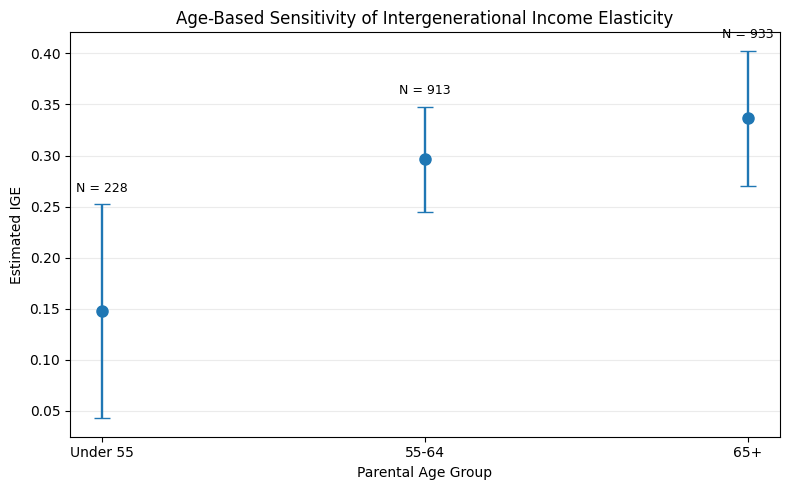

In [2]:

# ============================================================
# Age-Based Sensitivity Analysis
# Blog Post 6
# ============================================================

# Step 1: Average parental age across four waves
age_summary = (
    complete_annual
    .groupby(keys, as_index=False)
    .agg(
        parent_mean_age=("parent_age", "mean"),
        child_mean_age=("child_age", "mean")
    )
)

# Step 2: Combine age information with average income
age_sample = complete_multi.merge(
    age_summary,
    on=keys,
    how="inner",
    validate="one_to_one"
)

# Step 3: Define parental age groups
age_sample["age_group"] = pd.cut(
    age_sample["parent_mean_age"],
    bins=[0, 55, 65, float("inf")],
    labels=["Under 55", "55-64", "65+"],
    right=False
)

# Step 4: Estimate IGE within each age group
age_results = []

for group, df in age_sample.groupby(
    "age_group", observed=True
):
    estimate = regression(
        df,
        "parent_avg_income",
        "child_avg_income"
    )

    if estimate is not None:
        age_results.append({
            "age_group": str(group),
            "IGE": estimate["beta"],
            "ci_low": estimate["ci_low"],
            "ci_high": estimate["ci_high"],
            "n": estimate["n"],
            "mean_parent_age": df["parent_mean_age"].mean(),
            "mean_child_age": df["child_mean_age"].mean()
        })

age_results = pd.DataFrame(age_results)

print("\n=== Age-Based Sensitivity Analysis ===")
print(age_results.round(3).to_string(index=False))

age_results.to_csv(
    OUTPUT / "age_sensitivity_results.csv",
    index=False
)

# Step 5: Visualize age-specific IGE estimates
if not age_results.empty:

    fig, ax = plt.subplots(figsize=(8, 5))

    positions = np.arange(len(age_results))

    estimates = age_results["IGE"].to_numpy()

    lower_errors = (
        age_results["IGE"] -
        age_results["ci_low"]
    ).to_numpy()

    upper_errors = (
        age_results["ci_high"] -
        age_results["IGE"]
    ).to_numpy()

    ax.errorbar(
        positions,
        estimates,
        yerr=[lower_errors, upper_errors],
        fmt="o",
        capsize=6,
        markersize=8,
        linewidth=1.7
    )

    ax.set_xticks(
        positions,
        age_results["age_group"]
    )

    for i, row in age_results.reset_index(drop=True).iterrows():
        ax.annotate(
            f"N = {int(row['n']):,}",
            (i, row["ci_high"]),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    ax.set_xlabel("Parental Age Group")
    ax.set_ylabel("Estimated IGE")
    ax.set_title(
        "Age-Based Sensitivity of Intergenerational "
        "Income Elasticity"
    )

    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()

    plt.savefig(
        OUTPUT / "figure_age_sensitivity.png",
        dpi=300
    )

    plt.show()
